# K-NN Practice Example (Week 7 tutorial)

*Based on the DataCamp tutorial "K-Nearest Neighbors Classification with scikit-learn" listed on the last slide of the lecture (https://www.datacamp.com/tutorial/k-nearest-neighbor-classification-scikit-learn), with the scaling and elbow-method steps from the lecture added.*

**Problem:** the *Wine* dataset (UCI Machine Learning Repository, shipped with scikit-learn) holds 13 chemical measurements of 178 wines from three grape cultivars of the same Italian region. We train a **k-nearest-neighbours (K-NN)** classifier that predicts the cultivar of a wine from its measurements, and we choose the number of neighbours *k*.

**How to run:** this notebook runs in your browser on the course website, so there is nothing to install and nothing to download. Use **Run → Run All Cells**, or press **Shift+Enter** to run one cell at a time, in order. The first run loads scikit-learn, which takes a few seconds.

**Expected result:** with k = 5 on the raw measurements the test accuracy is only 0.648; after each measurement is scaled to mean 0 and standard deviation 1 (the "normalize each dimension by standard deviation" point of the lecture) it rises to 0.926. An error-rate-versus-k plot (the elbow method of the lecture), made with cross-validation on the training data, gives its lowest error rate (0.031) at k = 21, and the final model with k = 21 reaches a test accuracy of 0.963.

## 1. Imports
pandas shows the data as a table, Matplotlib draws the elbow plot, and scikit-learn provides the dataset, the train/test split, the scaler, the K-NN classifier and the accuracy score.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn import metrics
import warnings
# in the browser, a helper library of scikit-learn prints a harmless deprecation warning; hide it
warnings.filterwarnings("ignore", message="JsProxy.as_object_map", category=RuntimeWarning)

## 2. Load and explore the data
`load_wine()` returns the measurements (`wine.data`, one row per wine), the cultivar of each wine (`wine.target`: 0, 1 or 2) and their names. The table shows the first five wines. Look at the ranges: *proline* is in the hundreds or thousands, while *hue* is around 1.

In [2]:
wine = load_wine()
print('Features:', wine.feature_names)
print('Classes:', ', '.join(wine.target_names))
print('Data shape (wines, features):', wine.data.shape)

df = pd.DataFrame(wine.data, columns=wine.feature_names)
df['cultivar'] = wine.target
df.head()

Features: ['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium', 'total_phenols', 'flavanoids', 'nonflavanoid_phenols', 'proanthocyanins', 'color_intensity', 'hue', 'od280/od315_of_diluted_wines', 'proline']
Classes: class_0, class_1, class_2
Data shape (wines, features): (178, 13)


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,cultivar
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


## 3. Split into training and test data
We keep 30% of the wines aside as test data, as in the "Model Averaging" slides: the model never sees them while it learns, so its accuracy on them shows how well it predicts new wines. `stratify=wine.target` keeps the share of each cultivar the same in both parts, and `random_state=1` makes the split the same every time the notebook runs.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    wine.data, wine.target, test_size=0.3, random_state=1, stratify=wine.target)  # 70% train, 30% test
print('Training wines:', len(X_train), '  Test wines:', len(X_test))

Training wines: 124   Test wines: 54


## 4. K-NN with k = 5 on the raw measurements
`KNeighborsClassifier(n_neighbors=5)` stores the training wines (`fit`). For each test wine, `predict` finds the 5 training wines at the smallest Euclidean distance and returns their most frequent cultivar. The accuracy is the share of test wines that get the right cultivar.

In [4]:
knn = KNeighborsClassifier(n_neighbors=5)  # k = 5, Euclidean distance (the default)
knn.fit(X_train, y_train)                   # K-NN only stores the training data
y_pred = knn.predict(X_test)                # majority vote of the 5 nearest training wines
print('Accuracy (raw measurements, k = 5): %.3f' % metrics.accuracy_score(y_test, y_pred))

Accuracy (raw measurements, k = 5): 0.648


## 5. Scale the measurements first
The Euclidean distance adds up the squared differences of all 13 measurements, so *proline* (values up to about 1,700) decides almost alone which wines are "near". `StandardScaler` rescales every measurement to mean 0 and standard deviation 1, using the training data only. `make_pipeline` chains the scaler and the classifier, so the test data are scaled in the same way before the neighbours are searched.

In [5]:
scaled_knn = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5))  # scale, then K-NN
scaled_knn.fit(X_train, y_train)
y_pred = scaled_knn.predict(X_test)
print('Accuracy (scaled measurements, k = 5): %.3f' % metrics.accuracy_score(y_test, y_pred))
print()
print(metrics.confusion_matrix(y_test, y_pred))  # rows: true cultivar, columns: predicted cultivar

Accuracy (scaled measurements, k = 5): 0.926

[[18  0  0]
 [ 3 17  1]
 [ 0  0 15]]


## 6. Choose k with the elbow method
The lecture plots the error rate (1 − accuracy) for many values of k and looks for a range where it stays low. We must not choose k on the test data, because then the test accuracy would no longer show how well the model predicts *new* wines. Instead we use ten-fold cross-validation on the training data, as in the "Model Averaging" slides: the training wines are split into ten parts, each part serves once as validation data for a model trained on the other nine, and the ten error rates are averaged. The loop does this for every k from 1 to 39.

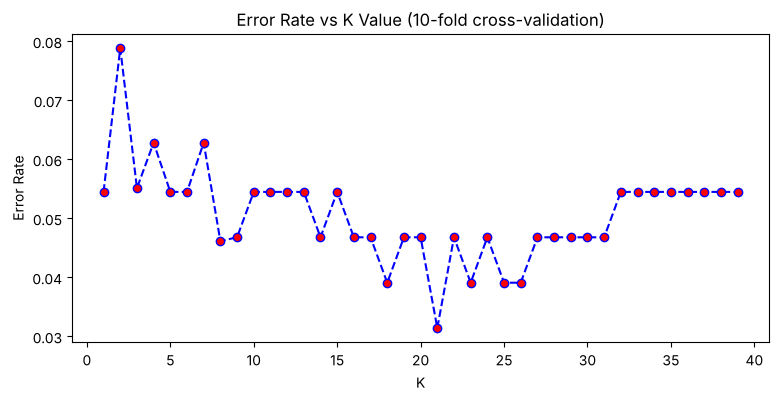

Lowest cross-validation error rate: 0.031, for k = 21


In [6]:
k_values = range(1, 40)
cv_error = []
for k in k_values:
    model = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k))
    accuracy = cross_val_score(model, X_train, y_train, cv=10)  # ten-fold cross-validation, training data only
    cv_error.append(1 - accuracy.mean())                         # average error rate over the ten folds

plt.figure(figsize=(9, 4))
plt.plot(k_values, cv_error, color='blue', linestyle='dashed', marker='o', markerfacecolor='red', markersize=6)
plt.title('Error Rate vs K Value (10-fold cross-validation)')
plt.xlabel('K')
plt.ylabel('Error Rate')
plt.show()

best_k = k_values[int(np.argmin(cv_error))]  # the k with the lowest cross-validation error
print('Lowest cross-validation error rate: %.3f, for k = %d' % (min(cv_error), best_k))

## 7. Final model
We train the scaled K-NN model with the chosen k on all training wines and measure its accuracy once on the test wines.

In [7]:
final_model = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=best_k))
final_model.fit(X_train, y_train)
print('Test accuracy (scaled measurements, k = %d): %.3f' % (best_k, final_model.score(X_test, y_test)))

Test accuracy (scaled measurements, k = 21): 0.963


**Try it:** in section 4, change `n_neighbors=5` to `n_neighbors=7` (the DataCamp tutorial also tries k = 7) and run the cells of section 4 again. Then do the same in section 5. Does the larger k help more on the raw or on the scaled measurements?

<details>
<summary>Show the answer</summary>

With k = 7 the accuracy on the raw measurements drops a little, from 0.648 to 0.630; on the scaled measurements it stays at 0.926. Changing k helps far less than scaling: on the raw measurements the "nearest" wines are mostly the ones with a similar *proline* value, whatever k is.
</details>

**What do you notice?** In the plot of section 6, k = 2 has the highest error rate, and k = 4 is worse than k = 3 and k = 5. Why are even values of k worse here?

<details>
<summary>Show the answer</summary>

With an even k the vote can end in a tie, for example 1 : 1 when k = 2. scikit-learn then picks the class that comes first in its list, which is often wrong. With an odd k a tie between two classes cannot happen, which is why the lecture suggests an odd k ("How do you decide the number of neighbours in KNN?"). With three classes a tie is still possible, but much rarer.
</details>